# SHAP analysis: what drives late-delivery risk?
**Delivery Risk Intelligence (DRI) · BAN6800 Module 4 · Gain Tawodzera**

This notebook explains the champion model registered in MLflow (`dri-late-delivery-classifier`, alias `champion`), using the frozen test period (purchases June to August 2018). It applies the Module 2 Explainability Framework:

| Audience | Question | Method in this notebook |
| --- | --- | --- |
| Analysts, Review Board | What does the model rely on overall? | Global SHAP importance and beeswarm (section 2) |
| Delivery operations | Why is this order risky? | Local SHAP waterfall and top-3 reasons (section 3) |
| Seller support | What would change the outcome? | Counterfactuals with DiCE (section 4) |

SHAP values are in log-odds of late delivery. The ~90 encoded columns are summed back to the 27 original features, so each explanation reads in business terms.

In [1]:
import json, warnings
warnings.filterwarnings("ignore")
import os, sys
sys.path.insert(0, os.path.abspath(".."))
import joblib, numpy as np, pandas as pd, shap, matplotlib.pyplot as plt
from src.models.data import FEATURES, NUMERIC, TARGET, load_modelling_frame, split
from src.models.explain import Explainer, PLAIN

meta = json.load(open("../models/dri_late_classifier.json"))
model = joblib.load("../models/dri_late_classifier.joblib")
thr = meta["threshold"]
s = split(load_modelling_frame("../data/processed/orders_model_ready.parquet"))
test = s["test"]
expl = Explainer(model, None, FEATURES, mean_encoded=meta.get("encoded_mean"))
print(f"Model: {meta['algorithm']} v{meta['version']}, threshold {thr:.4f}, test orders {len(test):,}")

Model: Logistic Regression v3, threshold 0.5003, test orders 18,603


## 1. Sanity check: SHAP values add up to the model's prediction

In [2]:
X = test.sample(4000, random_state=0).reset_index(drop=True)
G = expl.grouped(X)
logit = np.log(model.predict_proba(X[FEATURES])[:, 1] / (1 - model.predict_proba(X[FEATURES])[:, 1]))
recon = expl.base_value() + G.sum(axis=1)
print("max |base + sum(SHAP) - model log-odds| =", float(np.abs(recon - logit).max()).__round__(6))

max |base + sum(SHAP) - model log-odds| = 0.0


## 2. Global importance
Mean absolute SHAP value per original feature, over 4,000 test orders.

In [3]:
imp = G.abs().mean().sort_values(ascending=False)
table = pd.DataFrame({"feature": [PLAIN[f] for f in imp.index], "mean_abs_shap": imp.round(4).values})
table.head(12)

,feature,mean_abs_shap
0,Days promised to the customer,0.5967
1,"Delivery time in customer's state, last 30 days",0.4467
2,Promise slack vs recent delivery time,0.2795
3,Seller-to-customer distance,0.2330
4,Black Friday to Christmas period,0.2320
5,Seller's past handling time,0.2250
6,Customer's state,0.1852
7,Seller and customer in different states,0.1666
8,Order value,0.1222
9,Seller's state,0.1158


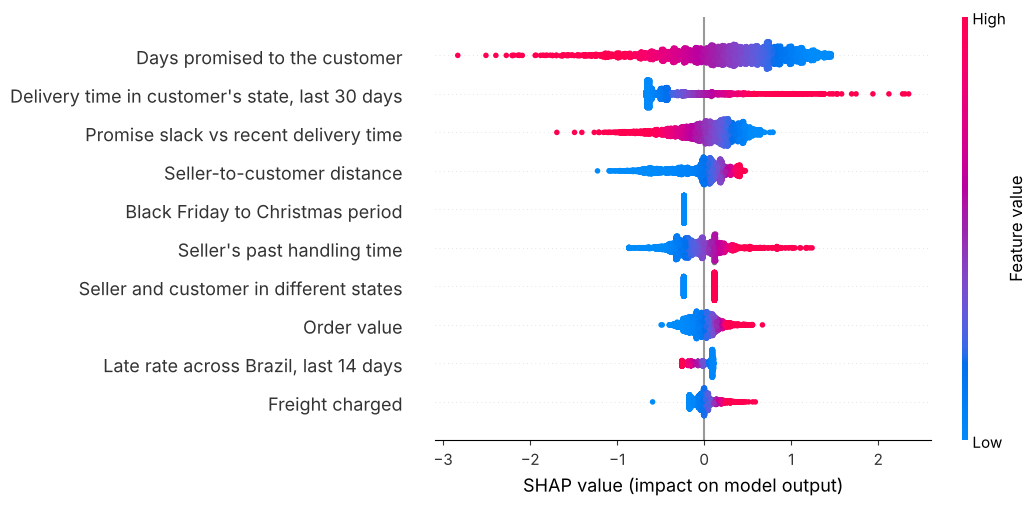

In [4]:
num_top = [f for f in imp.index if f in NUMERIC][:10]
e = shap.Explanation(values=G[num_top].to_numpy(), data=X[num_top].to_numpy(dtype=float),
                     feature_names=[PLAIN[f] for f in num_top])
shap.plots.beeswarm(e, max_display=10)

**Reading the beeswarm.** Each dot is one order. Red means a high value of that feature, blue a low value. Dots to the right push the order towards *late*. A short promise window (blue *Days promised*) pushes risk up, which is the clearest business signal. Long distances and a seller's poor track record also raise the risk.

## 3. Local explanations: individual orders

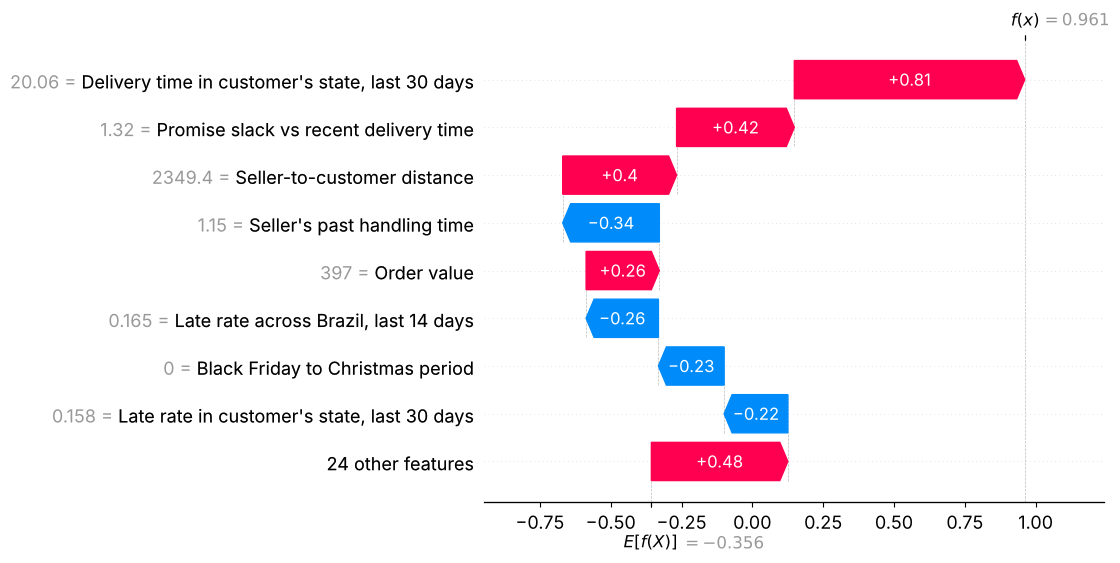

Risk score: 0.723 | actually late: True


,feature,reason,value,impact_log_odds
0,state_delivery_days_30d,"Delivery time in customer's state, last 30 days",20.06,0.813
1,promise_slack_days,Promise slack vs recent delivery time,1.32,0.415
2,distance_km,Seller-to-customer distance,2349.40,0.402


In [5]:
te = test.assign(score=model.predict_proba(test[FEATURES])[:, 1])
flagged = te[(te[TARGET] == 1) & (te.score >= thr) & (te.customer_region == "Northeast")]
i = int(flagged.score.sub(flagged.score.median()).abs().idxmin())
row = test.iloc[[i]]
g = expl.grouped(row).iloc[0]
shap.plots.waterfall(shap.Explanation(values=g.to_numpy(), base_values=expl.base_value(),
    data=np.array([row.iloc[0][f] for f in FEATURES], dtype=object), feature_names=[PLAIN[f] for f in FEATURES]),
    max_display=9)
print("Risk score:", round(float(te.loc[i, "score"]), 3), "| actually late:", bool(test.loc[i, TARGET]))
pd.DataFrame(expl.reasons(row))

The table above is exactly what the `/predict` endpoint returns as `top_reasons` for the operations team.

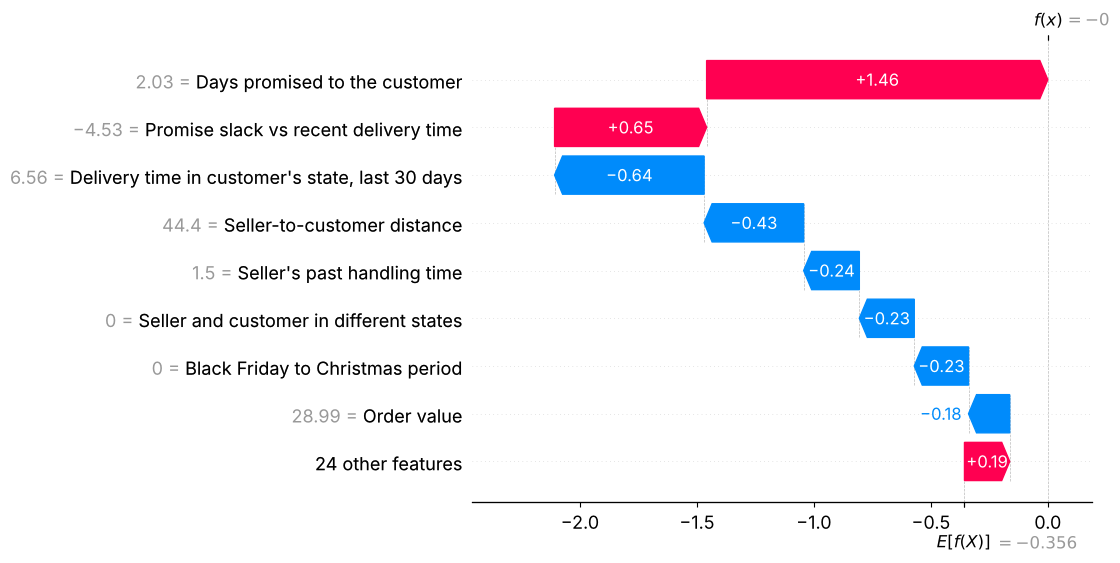

A late order just below the serving threshold: score 0.5000 vs threshold 0.5003


In [6]:
missed = te[(te[TARGET] == 1) & (te.score < thr)]
j = int(missed.score.idxmax())
row = test.iloc[[j]]
g = expl.grouped(row).iloc[0]
shap.plots.waterfall(shap.Explanation(values=g.to_numpy(), base_values=expl.base_value(),
    data=np.array([row.iloc[0][f] for f in FEATURES], dtype=object), feature_names=[PLAIN[f] for f in FEATURES]),
    max_display=9)
print(f"A late order just below the serving threshold: score {te.loc[j, 'score']:.4f} vs threshold {thr:.4f}")

## 4. Counterfactuals: what would need to change?
Generated with DiCE in `src/models/analyze.py`. Only actions Olist controls may change: a longer promise (promised days and slack move together) or a seller with a better track record. For the riskiest example DiCE finds no change within the allowed ranges; that is a finding too: some orders are risky whatever Olist does.

In [7]:
summary = json.load(open("../docs/evidence/model/analysis_summary.json"))
rows = []
for q in summary["counterfactuals"]["examples"]:
    for c in q["counterfactuals"]:
        rows.append({"order": q["order_key"][:8], "region": q["region"], "risk_now": q["score"],
                     "change": "; ".join(f"{PLAIN[f]}: {a} -> {b}" for f, (a, b) in c["changes"].items()),
                     "risk_after": c["new_score"]})
pd.DataFrame(rows)

,order,region,risk_now,change,risk_after
0,28a10026,Southeast,0.502,Promise slack vs recent delivery time: -0.19 -...,0.331
1,28a10026,Southeast,0.502,Seller's past handling time: 0.96 -> 0.81,0.488
2,28a10026,Southeast,0.502,Seller's past handling time: 0.96 -> 0.76,0.483
3,be04ff52,Northeast,0.631,Promise slack vs recent delivery time: 8.01 ->...,0.222
4,be04ff52,Northeast,0.631,Promise slack vs recent delivery time: 8.01 ->...,0.196
5,be04ff52,Northeast,0.631,Promise slack vs recent delivery time: 8.01 ->...,0.262


In [8]:
pe = summary["counterfactuals"]["promise_extension"]
print(f"Flagged test orders: {pe['orders']:,}. Median extra promise days to fall below the threshold: {pe['median_days']:.0f}.")
print(f"Resolved within 7 extra days: {pe['share_resolved_within_7_days']:.0%}.")
pd.Series(pe["median_days_by_region"], name="median extra days needed")

Flagged test orders: 3,154. Median extra promise days to fall below the threshold: 5.
Resolved within 7 extra days: 70%.


Central-West    4.0
North           7.0
Northeast       7.0
South           4.0
Southeast       4.0
Name: median extra days needed, dtype: float64

## 5. Takeaways for the business
1. **The promise is the biggest lever.** *Days promised* and *promise slack* are two of the top three drivers: longer promises lower the risk. For flagged orders, a median of 5 extra promise days removes the flag, which supports the Module 1 action "update the delivery date".
2. **Geography enters through recent delivery times and distance, not just the state label.** This is why removing the state and region columns did not change the regional pattern (fairness report, `docs/fairness_report.md`).
3. **Seller history adds little.** Removing it does not lower ROC-AUC on the test period (sensitivity analysis), so it is a candidate to drop in the next version.
4. **Peak season dominates when it applies.** In the API example (a November order), *Black Friday to Christmas* is the top reason.